In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, '/home/biel/HODDIES')
for module_name in list(sys.modules):
    if module_name == 'HODDIES' or module_name.startswith('HODDIES.'):
        del sys.modules[module_name]

import numpy as np
import matplotlib.pyplot as plt
from HODDIES import HOD
import HODDIES

print(f'Using HODDIES from {HODDIES.__file__}')


Using HODDIES from /home/biel/HODDIES/HODDIES/__init__.py


In [2]:
from cosmoprimo.fiducial import DESI
desi = DESI()
desi.get_params()

{'k_pivot': 0.05,
 'beta_s': 0.0,
 'r': 0.0,
 'n_t': -0.0,
 'alpha_t': -0.0,
 'T_cmb': array(2.7255),
 'T_ncdm_over_cmb': array([0.71611]),
 'reionization_width': 0.5,
 'A_L': 1.0,
 'cs2_fld': array(1.),
 'non_linear': '',
 'modes': ['s'],
 'lensing': False,
 'z_pk': array([ 0.        ,  0.01189061,  0.04756243,  0.10701546,  0.1902497 ,
         0.29726516,  0.42806183,  0.58263971,  0.76099881,  0.96313912,
         1.18906064,  1.43876338,  1.71224732,  2.00951249,  2.33055886,
         2.67538644,  3.04399524,  3.43638526,  3.85255648,  4.29250892,
         4.75624257,  5.24375743,  5.75505351,  6.2901308 ,  6.8489893 ,
         7.43162901,  8.03804994,  8.66825208,  9.32223543, 10.        ]),
 'kmax_pk': 10.0,
 'ellmax_cl': 2500,
 'YHe': 'BBN',
 'use_ppf': True,
 'tau_reio': 0.0544,
 'h': array(0.6736),
 'A_s': array(2.083e-09),
 'n_s': 0.9649,
 'alpha_s': 0.0,
 'w0_fld': array(-1.),
 'wa_fld': array(0.),
 'Omega_k': np.float64(0.0),
 'Omega_b': array(0.04930169),
 'Omega_cdm': ar

In [3]:
boxsize = 1024.0
redshift = 0.506

FOF_OUTPUT = Path('/scratch/biel/LCDM/snapshot_LCDM_z{:.3f}/hod_fof/halos200c_hod_arr.npy'.format(redshift))
FOF_METADATA = Path(str(FOF_OUTPUT) + '.json')
PARAM_FILE = '/home/biel/Hi-COLA/Notebooks/HOD_parameter_file_z{:.3f}.yaml'.format(redshift)

print(f'FoF output: {FOF_OUTPUT}')
print(f'Exists: {FOF_OUTPUT.exists()}')


FoF output: /scratch/biel/LCDM/snapshot_LCDM_z0.506/hod_fof/halos200c_hod_arr.npy
Exists: True


In [4]:
if not FOF_OUTPUT.exists():
    raise FileNotFoundError(
        f'Missing {FOF_OUTPUT}. Run /home/biel/Hi-COLA/hod_fof72.sh first, '
        'then come back to this notebook.'
    )

arr = np.load(FOF_OUTPUT)
print(f'Loaded {len(arr):,} halos')
print(arr.dtype)

if FOF_METADATA.exists():
    with FOF_METADATA.open() as f:
        fof_metadata = json.load(f)
    print(json.dumps(fof_metadata, indent=2))
else:
    fof_metadata = {}


Loaded 4,773,203 halos
[('x', '<f8'), ('y', '<f8'), ('z', '<f8'), ('vx', '<f8'), ('vy', '<f8'), ('vz', '<f8'), ('Mh', '<f8'), ('log10_Mh', '<f8'), ('Rh', '<f8'), ('Rs', '<f8'), ('c', '<f8'), ('Vrms', '<f8'), ('halo_id', '<i8')]
{
  "Vrms_definition": "sqrt(sum_i(<v_i^2> - <v_i>^2)) over FOF member particles",
  "boxsize": 1024.0,
  "halos": 4773203,
  "linking_length": 0.2,
  "mass_units": "Msun/h",
  "mdef": "200c",
  "mpi_ranks": 512,
  "nmin": 30,
  "output": "/scratch/biel/LCDM/snapshot_LCDM_z0.506/hod_fof/halos200c_hod_arr.npy",
  "particle_mass_code_units": 3.026165999280917,
  "particle_mass_msun_h": 30261659992.80917,
  "particle_type": 1,
  "radius_units": "kpc/h",
  "redshift": 0.506,
  "snapshot": "/scratch/biel/LCDM/snapshot_LCDM_z0.506/gadget_z0.506.*",
  "velocity_units": "km/s"
}


In [5]:
print('Mass range:', arr['Mh'].min(), arr['Mh'].max())
print('log10_Mh range:', arr['log10_Mh'].min(), arr['log10_Mh'].max())
print('Position mins:', np.min(np.vstack([arr['x'], arr['y'], arr['z']]).T, axis=0))
print('Position maxs:', np.max(np.vstack([arr['x'], arr['y'], arr['z']]).T, axis=0))


Mass range: 938111459777.0842 2092926666762675.0
log10_Mh range: 11.97225444124727 15.320754011531108
Position mins: [6.36223704e-05 1.65684964e-04 9.05315392e-06]
Position maxs: [1023.99993896 1023.99993896 1023.99993896]


In [6]:
HOD_obj = HOD(hcat_file=arr, **{'hcat': {'boxsize': boxsize}}, param_file=PARAM_FILE)
HOD_obj.args['hcat']['z_simu'] = redshift
HOD_obj.cosmo = desi

Set number of threads to 32
Initialize custom cosmology from the "cosmo" parameters


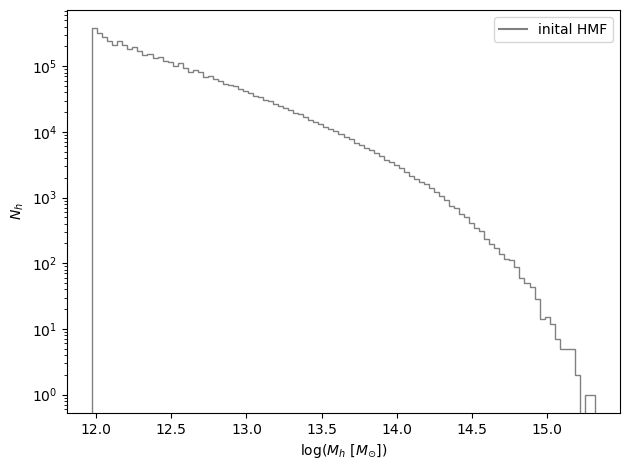

In [7]:
HOD_obj.plot_initial_HMF()

In [8]:
cat = HOD_obj.make_mock_cat(tracers='LRG', fix_seed=42)

Create mock catalog for ['LRG']
Run HOD for LRG
Set density to 0.0007 gal/Mpc/h
HOD Computed 10.596001148223877
Start satellite assignement


/home/biel/HODDIES/HODDIES/utils.py:502: NumbaPerformanceWarning: 
The keyword argument 'parallel=True' was specified but no transformation for parallel execution was possible.

To find out why, try turning on parallel diagnostics, see https://numba.readthedocs.io/en/stable/user/parallel.html#diagnostics for help.

File "../../HODDIES/HODDIES/utils.py", line 418:
@njit(fastmath=True)
def get_etavir_nfw(c): 
^

  etaVir = get_etavir_nfw(c[i])*nfw_rescale
/home/biel/miniconda3/envs/hicola/lib/python3.11/site-packages/numba/parfors/parfor.py:2399: NumbaPerformanceWarning: 
prange or pndindex loop will not be executed in parallel due to there being more than one entry to or exit from the loop (e.g., an assertion).

File "../../HODDIES/HODDIES/utils.py", line 490:
def compute_fast_NFW(x_h, y_h, z_h, vx_h, vy_h, vz_h, c, M, Rvir, rd_pos, rd_vel, exp_frac=0, exp_scale=1, nfw_rescale=1, vrms_h=None, f_sigv=None, v_infall=None, vel_sat='NFW', Nthread=32, seed=None):
    <source elided>
    hsta

Satellite assignement done 4.611004829406738
LRG mock catalogue done 4.727002143859863
639314 central galaxies, 111477 satellites, fraction of satellite 0.15 
Done overall time  LRG 15.37748408317566


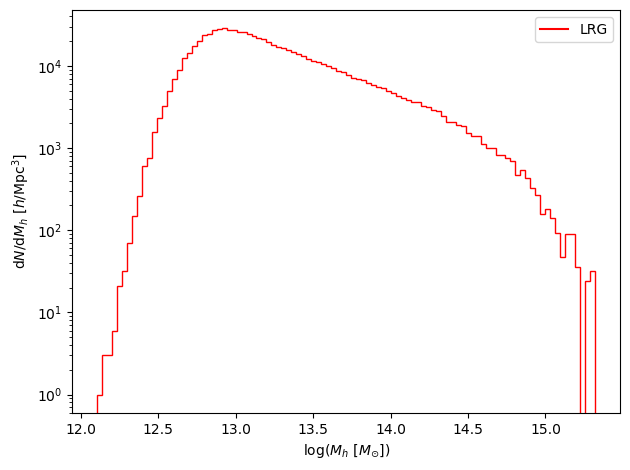

In [9]:
HOD_obj.plot_HMF(cat,tracer='LRG')

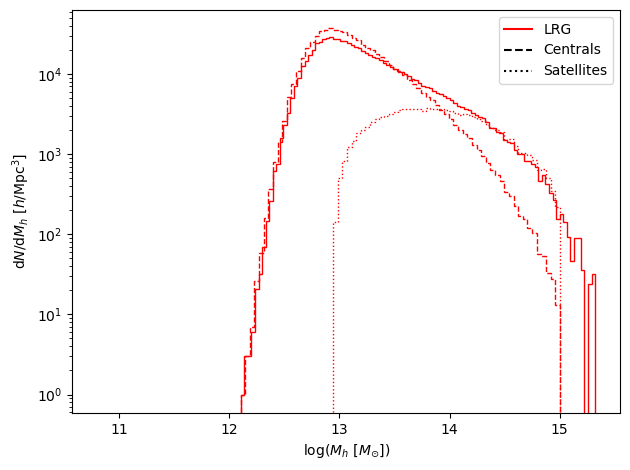

In [10]:
HOD_obj.plot_HMF(cat, show_sat=True, tracer='LRG')

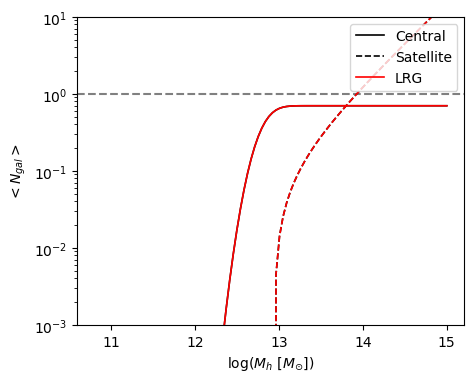

In [12]:
HOD_obj.HOD_plot()

In [13]:
rp, wp = HOD_obj.get_wp(cat, tracers='LRG')
s, xi = HOD_obj.get_2PCF(cat, tracers='LRG')

#Compute wp for LRG...
Done in 12.974 s
#Compute xi(s,mu) using l=[0, 2] for LRG...
#Done in 10.082 s


In [14]:
HOD_obj.args['LRG']['link_sat_to_central'] = True

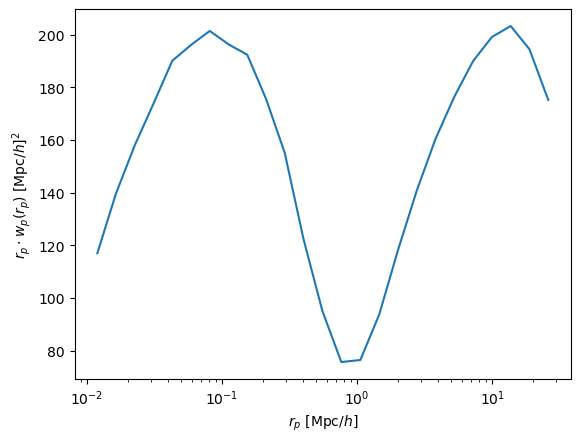

In [15]:
plt.plot(rp,rp*wp)
plt.xscale('log')
plt.xlabel('$r_p$ [$\mathrm{{Mpc}}/h$]')
plt.ylabel(r'$r_p \cdot w_p(r_p)$ [$\mathrm{{Mpc}}/h$]$^2$')
plt.show()

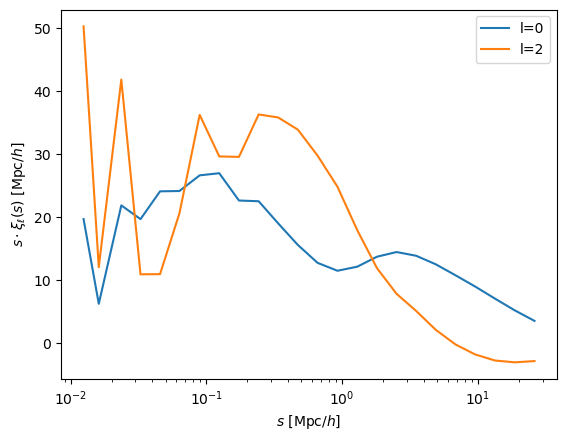

In [16]:
plt.plot(s,s*xi[0], label='l=0')
plt.plot(s,s*xi[1], label='l=2')
plt.xscale('log')
plt.xlabel('$s$ [$\mathrm{{Mpc}}/h$]')
plt.ylabel(r'$s \cdot \xi_{\ell}(s)$ [$\mathrm{{Mpc}}/h$]')
plt.legend()
plt.show()